<a href="https://colab.research.google.com/github/Seamuscs/Brent-and-WTI-spread-analysis/blob/main/Part_II_Statistical_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part II - Statistical Analysis**
In this part I want to do more advanced statistical analysis, for this I will remove one of the limitations from the last part. I will work with futures instead as this is what electronic trades are made on. Sadly, my university will not let me use their Bloomberg terminal but I will use a free alternative and only starts in 2007, though our objective is not to be profitable but to analyse and learn.

#  2.1 - Futures

In [22]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')
df = pd.read_parquet('/content/drive/MyDrive/Brent_and_WTI_spread_analysis_project/adjusted_spot_data.parquet')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
fut = yf.download(["BZ=F", "CL=F"], start="2007-01-01")["Close"]
fut.columns = ["brent_fut", "wti_fut"]
fut.dropna(inplace=True)
fut

/tmp/ipykernel_488/829486332.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  fut = yf.download(["BZ=F", "CL=F"], start="2007-01-01")["Close"]
[*********************100%***********************]  2 of 2 completed


,brent_fut,wti_fut
Date,,
2007-07-30,75.739998,76.830002
2007-07-31,77.050003,78.209999
2007-08-01,75.349998,76.529999
2007-08-02,75.760002,76.860001
2007-08-03,74.750000,75.480003
...,...,...
2026-10-26,115.809998,101.760002
2026-10-27,113.879997,99.900002
2026-10-28,115.320000,102.779999


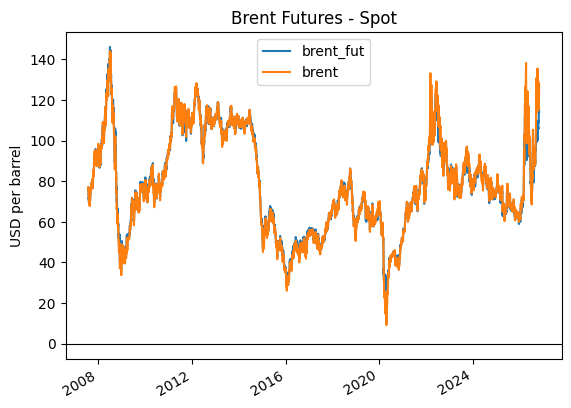

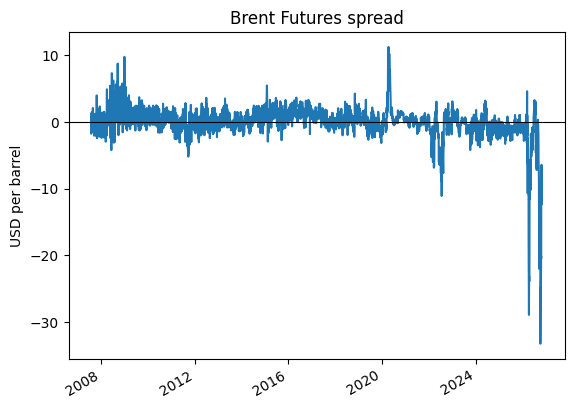

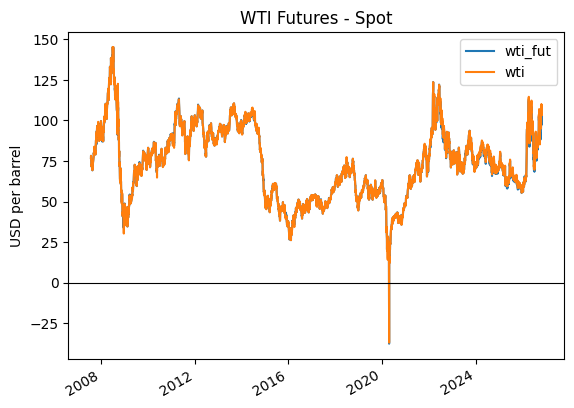

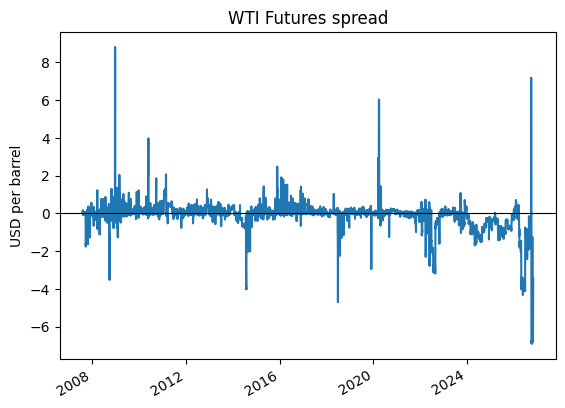

In [24]:
comp_1  = pd.concat([fut["brent_fut"], df["brent"]], axis=1, join="inner")
comp_1.columns = ["brent_fut", "brent"]
ex = comp_1.plot()
ex.set_title("Brent Futures - Spot")
ex.set_ylabel("USD per barrel")
ex.axhline(0, color="black", linewidth=0.8)
plt.show()

comp_1["fut_spread"] = comp_1["brent_fut"] - comp_1["brent"]
fx = comp_1["fut_spread"].plot()
fx.set_title("Brent Futures spread")
fx.set_ylabel("USD per barrel")
fx.axhline(0, color="black", linewidth=0.8)
plt.show()

comp_2  = pd.concat([fut["wti_fut"], df["wti"]], axis=1, join="inner")
comp_2.columns = ["wti_fut", "wti"]
gx = comp_2.plot()
gx.set_title("WTI Futures - Spot")
gx.set_ylabel("USD per barrel")
gx.axhline(0, color="black", linewidth=0.8)
plt.show()

comp_2["fut_spread"] = comp_2["wti_fut"] - comp_2["wti"]
hx = comp_2["fut_spread"].plot()
hx.set_title("WTI Futures spread")
hx.set_ylabel("USD per barrel")
hx.axhline(0, color="black", linewidth=0.8)
plt.show()

As you can see by the speads of each of the benchmarks futures, they can change quite drastically. I hope from Part I you can see that the sharp deviations in spread line up with key world events. This is because of tumultous markets, by definition futures and spot prices are quite different and this difference is emphasised when prices jump around

# 2.2 - Testing for mean reversion

As aforementioned in the last part, means change after major economic events but the question this time is, do prices eventually fall back to the mean save for some 'noise'? There is no yes or no answer here other than to find out and test for it. To test for mean reversion, I shall first describe how and what we use to do it.

There are multiple ways of testing for mean-reversion. Using a diverse range of test also strengthens the reliability of any model or conclusion we produce. I will detail a more mathematical derivation in the appendix of the repository. The first one we shall use is the ADF (Augmented Dickey-Fuller) Test.

We let $P_t$ be the time series of our futures prices of our Brent - WTI spread with t indexed in time by our dates. The ADF Test will take in our data and return us with a test statistic. The null and alternative hypthothesis are such:

*   $H_0$ Null hypothesis: $P_t$ has a unit root meaning it is non stationary and so not mean-reverting
*   $H_1$ Alternative hypothesis: $P_t$ has no unit root meaning it is stationary and so mean-reverts





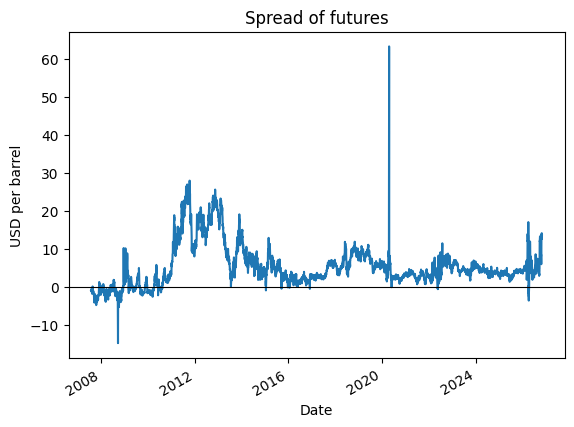

In [25]:
futures = pd.concat([fut["brent_fut"], fut["wti_fut"]], axis=1, join="inner")
futures["spread_fut"] = futures["brent_fut"] - futures["wti_fut"]

plot_1 = futures['spread_fut'].plot()
plot_1.set_title("Spread of futures")
plot_1.set_ylabel("USD per barrel")
plot_1.axhline(0, color="black", linewidth=0.8)
plt.show()

I quickly made a data frame for our futures prices for ease of use and gave us a plot. It will be important to consider this as a visual reference when thinking about the limitations of some of our tests.

In [26]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

adfuller(futures["spread_fut"])

/tmp/ipykernel_488/2103045991.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adfuller(futures["spread_fut"])


(-3.476698072407482,
 0.008606096158448364,
 23,
 4769,
 {'1%': np.float64(-3.4317219486911417),
  '5%': np.float64(-2.862146246504019),
  '10%': np.float64(-2.5670927068593774)},
 np.float64(15673.277151569206))

The ADF test concludes that $P_t$ mean reverts with a lag of 23 and is a critical value for 1%, 5% and 10% significance levels. This alone is only one test and the ADF test has its limitations. Which is why next we will use KPSS test.

The KPSS is almost always used in conjuction with the ADF test as their hypotheses are reversed essentially. The null and alternate hypothesis for the KPSS test are such:



In [28]:
from statsmodels.tsa.stattools import kpss
kpss(futures["spread_fut"])

/tmp/ipykernel_488/3758855121.py:2: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss(futures["spread_fut"])


(np.float64(0.7192746951829725),
 np.float64(0.011793209528820682),
 41,
 {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739})

Still ongoing...